# 의존성으로 Agent 주입

**이 노트북에서 할 일**

1. 처리 함수의 매개변수에 의존성을 적어, 라이브러리가 요청마다 값을 넘겨 주게 합니다.
2. 실습 앱을 가져와, 처리 함수 `chat`이 받는 의존성 셋과 접근 토큰 검사를 봅니다.
3. 시간 제한을 재정의한 채 두면 다음 테스트도 504를 받는 것을 보고, 재정의를 비워 고칩니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
예상 비용도 0달러입니다.
실습 앱의 에이전트 그래프는 모델을 쓰지 않고, 정해 둔 말로 답합니다.
그래서 다시 실행해도 같은 값이 나와야 합니다.

요청은 같은 노트북 안에서 앱 객체로 바로 들어갑니다.
서버 프로그램을 따로 띄우지 않고, 네트워크와 포트를 쓰지 않습니다.
실습 폴더의 앱 파일을 가져오고 읽기만 하며, 쓰는 파일은 없습니다.

걸린 시간은 재지 않았습니다.
이 절은 앞 챕터에서 배운 함수를 쓰지 않아, 가져오는 도구 파일도 없습니다.

**기준 버전** — 첫 셀에서 패키지 여섯을 설치합니다.
판은 fastapi 0.135.0, httpx 0.28.1, pydantic 2.12.5, starlette 1.6.0입니다.
패키지 langgraph 1.2.11과 langchain 1.4.0은 실습 앱 파일이 가져오는 패키지입니다.
여섯 모두 실습 폴더 잠금과 같은 판입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~5절을 읽습니다.
의존성과 재정의를 보고, 남은 재정의가 다음 테스트를 바꾸는 자리를 Before·After로 봅니다.
6절은 넣는 값 하나를 바꿔 보는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part7/ch30-fastapi-serving`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 초록 상자 요청 GET /limit 두 번 보냄에서 회색 상자 라이브러리가 요청마다 제공 함수를 부름으로 화살표가 갑니다. 이어서 파란 상자 제공 함수 get_limit 내놓는 값 2.0과 파란 상자 처리 함수 show_limit 매개변수 limit: LimitDep을 지나 노란 상자 응답 두 번 200 limit 2.0으로 이어집니다. 제공 함수 상자에서 노란 상자 불린 기록 get_limit 두 번으로도 화살표가 가는 그림](attachment:02-1-요청마다-불리는-제공-함수.png)

위에서 아래로 읽습니다.
초록 상자는 보낸 요청이고, 회색 상자는 라이브러리가 하는 일입니다.
파란 상자 둘은 노트북 2절에서 우리가 만든 제공 함수와 처리 함수입니다.
노란 상자 둘은 2절 출력의 응답과 불린 기록입니다.
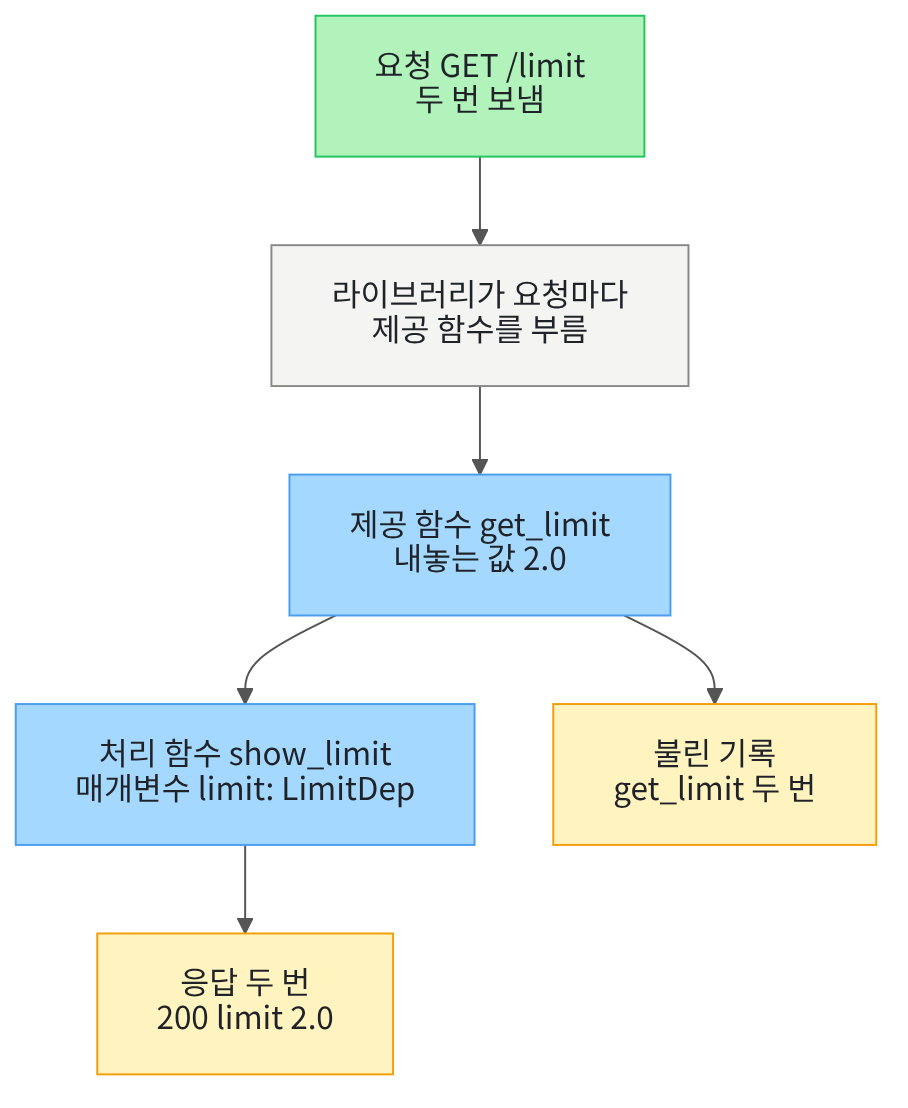

## 1. 준비

01절에서는 앱 객체와 처리 함수를 노트북에서 만들었습니다.
이 절은 처리 함수가 쓸 값을 라이브러리가 넘겨 주게 하는 방법을 봅니다.
제목의 주입은 FastAPI 문서의 말 injection을 옮긴 말로, 그렇게 값을 넘겨 주는 일을 가리킵니다.
이 교재 본문에서는 「처리 함수에 값을 넘겨 주기」라고 부릅니다.
제목의 Agent는 실습 앱의 에이전트 그래프입니다.

첫 셀은 패키지 여섯을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "fastapi==0.135.0" "httpx==0.28.1" "pydantic==2.12.5" "starlette==1.6.0" "langgraph==1.2.11" "langchain==1.4.0"
from importlib.metadata import version

print("fastapi:", version("fastapi"))
print("httpx:", version("httpx"))
print("pydantic:", version("pydantic"))
print("starlette:", version("starlette"))
print("langgraph:", version("langgraph"))
print("langchain:", version("langchain"))

Note: you may need to restart the kernel to use updated packages.
fastapi: 0.135.0
httpx: 0.28.1
pydantic: 2.12.5
starlette: 1.6.0
langgraph: 1.2.11
langchain: 1.4.0


**결과 읽기** — 출력 줄 `fastapi: 0.135.0`과 `langgraph: 1.2.11`이 보입니다.
여섯 모두 실습 폴더 잠금과 같은 판입니다.
패키지 fastapi·httpx·pydantic·starlette는 01절에서 쓴 넷입니다.
패키지 langgraph와 langchain은 3절에서 가져올 실습 앱 파일이 가져옵니다.
이 절은 모델 객체를 만들지 않습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
표시 `Annotated`는 Ch 13 02절에서 리듀서를 적을 때 쓴 이름입니다.
함수 `Depends`는 패키지 fastapi에서 가져오고, 2절에서 뜻을 풉니다.

In [2]:
# 이 절에서 쓸 이름을 가져옵니다(os·typing은 Python에 들어 있는 모듈입니다)
import os
from typing import Annotated
from fastapi import Depends, FastAPI
from fastapi.testclient import TestClient

print("가져온 fastapi 이름:", "Depends, FastAPI, TestClient")

가져온 fastapi 이름: Depends, FastAPI, TestClient


**결과 읽기** — 출력 줄 `가져온 fastapi 이름: Depends, FastAPI, TestClient`가 보입니다.
이 노트북에는 API 키를 확인하는 셀이 없습니다.
모델을 부르지 않기 때문입니다.

## 2. 의존성으로 처리 함수에 값 넘기기

처리 함수가 쓸 값을 몸통에서 만들지 않고, 라이브러리가 요청마다 넘겨 주게 할 수 있습니다.
패키지 fastapi는 이런 약속을 의존성(dependency)이라고 부릅니다.
도서관에 책을 신청해 두면, 자리에 앉을 때마다 사서가 그 책을 책상에 놓아 주는 것과 같습니다.
이 절에서는 매개변수 힌트에 `Depends(get_limit)`를 적어, 함수 `get_limit`이 내놓는 값을 받습니다.
먼저 연습용 앱 객체와, 기록을 적을 빈 목록을 만듭니다.

In [3]:
# 연습용 앱 객체와, 제공 함수가 불린 기록을 적을 빈 목록을 만듭니다
demo_app = FastAPI(title="연습 앱")
provider_calls = []
print("앱 이름:", demo_app.title)

앱 이름: 연습 앱


**결과 읽기** — 출력 줄 `앱 이름: 연습 앱`이 보입니다.
목록 `provider_calls`에는 아래 함수가 불릴 때마다 함수 이름을 적습니다.
01절에서 몸통에 들어온 값을 목록 `body_inputs`에 적은 방법과 같습니다.

다음 셀은 처리 함수에 넘길 값을 만들어 내놓는 함수를 정의합니다.
이 챕터에서는 이런 함수를 제공 함수라고 부릅니다.
값은 시간 제한 2.0초이고, 불릴 때마다 목록에 이름을 적습니다.

In [4]:
# 처리 함수에 넘길 시간 제한 초를 내놓는 제공 함수를 정의합니다
async def get_limit():
    # 불릴 때마다 목록에 이름을 적습니다(몇 번 불렸는지 보려는 줄입니다)
    provider_calls.append("get_limit")
    return 2.0

**결과 읽기** — 정의 셀이라 출력이 없습니다.
정의 줄이 `async def`인 비동기 함수이고, 01절의 처리 함수처럼 라이브러리가 await로 부릅니다.

다음 셀은 처리 함수의 매개변수 힌트에 쓸 이름 `LimitDep`을 만듭니다.
표시 `Annotated`의 첫 자리는 자료형 `float`, 둘째 자리는 `Depends(get_limit)`입니다.
Ch 13 02절에서는 둘째 자리에 합칠 함수를 적었고, 여기서는 값을 줄 함수를 적습니다.
함수 `Depends`에는 `get_limit`을 부르지 않고, 괄호 없이 함수 자체를 넘깁니다.

In [5]:
# 자료형 float 옆에 「get_limit이 내놓는 값」이라는 의존성을 적어, 이름 LimitDep에 담습니다
LimitDep = Annotated[float, Depends(get_limit)]

**결과 읽기** — 이름을 만드는 셀이라 출력이 없습니다.
FastAPI 문서는 이렇게 표시를 이름에 담아, 여러 처리 함수에서 함께 쓰는 모양을 보여 줍니다.
실습 앱 파일도 같은 모양으로 적혀 있고, 3절에서 그 줄을 봅니다.

다음 셀은 GET `/limit`에 처리 함수를 잇습니다.
매개변수 `limit`의 힌트가 `LimitDep`입니다.
라이브러리는 요청이 오면 `get_limit`을 불러, 내놓은 값을 `limit`에 넣고 처리 함수를 부릅니다.

In [6]:
# 요청 방식 GET과 요청 주소 /limit의 짝에, 시간 제한 초를 받는 처리 함수를 잇습니다
@demo_app.get("/limit")
async def show_limit(limit: LimitDep):
    return {"limit": limit}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
처리 함수 몸통에는 `get_limit`을 부르는 줄이 없습니다.
값을 만드는 일은 제공 함수가, 제공 함수를 부르는 일은 라이브러리가 맡습니다.

다음 셀은 시험용 클라이언트로 같은 요청을 두 번 넣습니다.
실행 전에 예상해 봅니다.
요청 두 번에 제공 함수는 몇 번 불릴까요?

In [7]:
# 같은 요청을 두 번 넣고, 응답과 제공 함수가 불린 기록을 봅니다
demo_client = TestClient(demo_app)
first_response = demo_client.get("/limit")
second_response = demo_client.get("/limit")
print("첫 응답:", first_response.status_code, first_response.json())
print("둘째 응답:", second_response.status_code, second_response.json())
print("제공 함수가 불린 기록:", provider_calls)

첫 응답: 200 {'limit': 2.0}
둘째 응답: 200 {'limit': 2.0}
제공 함수가 불린 기록: ['get_limit', 'get_limit']


**결과 읽기** — 출력 줄 `첫 응답: 200 {'limit': 2.0}`과 `둘째 응답: 200 {'limit': 2.0}`이 보입니다.
기록은 `['get_limit', 'get_limit']`이고, 요청 한 번에 제공 함수가 한 번씩 불렸습니다.
처리 함수는 제공 함수가 내놓은 값을 매개변수로 받아 그대로 내놓았습니다.

이제 시험 때 제공 함수를 다른 함수로 바꿔 끼워 봅니다.
다음 셀은 바꿔 낄 함수로, 시간 제한 0.5초를 내놓는 함수를 정의합니다.

In [8]:
# 시험 때 바꿔 낄, 시간 제한 0.5초를 내놓는 함수를 정의합니다
async def get_short_limit():
    return 0.5

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 함수는 목록에 아무것도 적지 않습니다.

앱 객체에는 재정의 딕셔너리 `dependency_overrides`가 있습니다.
원래 제공 함수를 키로, 바꿔 낄 함수를 값으로 적으면 라이브러리가 값 쪽 함수를 부릅니다.
이렇게 제공 함수를 바꿔 끼우는 일을 이 챕터에서는 재정의(override)라고 부릅니다.
다음 셀은 연습 앱에 재정의를 적고, 기록을 비운 뒤 같은 요청을 넣습니다.

In [9]:
# 재정의 딕셔너리에 원래 함수를 키로, 바꿔 낄 함수를 값으로 적고 다시 요청합니다
demo_app.dependency_overrides[get_limit] = get_short_limit
provider_calls = []
override_response = demo_client.get("/limit")
print("응답:", override_response.status_code, override_response.json())
print("제공 함수가 불린 기록:", provider_calls)
print("재정의 딕셔너리의 키 수:", len(demo_app.dependency_overrides))

응답: 200 {'limit': 0.5}
제공 함수가 불린 기록: []
재정의 딕셔너리의 키 수: 1


**결과 읽기** — 출력 줄 `응답: 200 {'limit': 0.5}`와 `제공 함수가 불린 기록: []`이 보입니다.
처리 함수는 그대로인데, 바꿔 낀 함수가 내놓은 값을 받았습니다.
원래 제공 함수 `get_limit`은 한 번도 불리지 않았습니다.

출력 줄 `재정의 딕셔너리의 키 수: 1`도 봅니다.
재정의는 앱 객체의 딕셔너리에 적힌 값이라, 이 셀이 끝난 뒤에도 남아 있습니다.
남은 재정의가 무엇을 일으키는지는 4절에서 실습 앱으로 봅니다.

## 3. 실습 앱 가져오기

이 챕터의 앱은 실습 폴더 맨 위의 폴더 `agent_service/`에 있습니다.
다음 셀은 01절 2절과 같은 파일 위치 셀로, 후보 셋 가운데 실습 폴더를 고릅니다.

In [10]:
# 노트북을 연 자리에서 본 실습 폴더의 위치를 후보 셋 가운데에서 고릅니다
candidates = ["..", ".", "labs/part7/ch30-fastapi-serving"]
lab_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/agent_service/schemas.py"):
        lab_path = candidate
        break
print("실습 폴더를 찾았는가:", lab_path is not None)
assert lab_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

실습 폴더를 찾았는가: True


**결과 읽기** — 출력 줄 `실습 폴더를 찾았는가: True`가 보입니다.
고른 후보는 연 자리마다 달라서 출력하지 않습니다.

01절은 형식 파일 하나만 실행해 읽었습니다.
앱 파일 `app.py`는 같은 폴더의 다른 파일에서 이름을 가져오므로, 그렇게 읽을 수 없습니다.
그래서 다음 셀은 작업 폴더를 실습 폴더로 옮긴 뒤, 폴더 `agent_service`에서 이름을 가져옵니다.
함수 `os.chdir`는 작업 폴더를 옮기는 함수입니다.
가져오는 이름은 앱 객체 `app`과 제공 함수 `get_agent`·`get_timeout`입니다.

In [11]:
# 작업 폴더를 실습 폴더로 옮기고, 앱 파일에서 앱 객체와 제공 함수 둘을 가져옵니다
os.chdir(lab_path)
from agent_service.app import app, get_agent, get_timeout
print("가져온 앱 이름:", app.title)
print("재정의 딕셔너리의 키 수:", len(app.dependency_overrides))

가져온 앱 이름: 교육용 Agent API
재정의 딕셔너리의 키 수: 0


**결과 읽기** — 출력 줄 `가져온 앱 이름: 교육용 Agent API`와 `재정의 딕셔너리의 키 수: 0`이 보입니다.
실습 앱 파일이 만든 앱 객체이고, 아직 재정의가 하나도 없습니다.

다음 셀은 앱 파일을 글로 읽어, 의존성을 적은 줄만 출력합니다.
처리 함수 `chat`의 정의 줄도 함께 출력합니다.
문장 `with open(...)`은 Ch 2 05절에서 파일을 열 때 쓴 모양입니다.

In [12]:
# 앱 파일을 글로 읽어, 의존성을 적은 줄과 처리 함수 chat의 정의 줄만 출력합니다
with open("agent_service/app.py", encoding="utf-8") as app_file:
    app_text = app_file.read()
print("의존성을 적은 줄과 chat의 정의 줄:")
for line in app_text.splitlines():
    if "Depends(" in line or line.startswith("async def chat("):
        print(line)

의존성을 적은 줄과 chat의 정의 줄:
AgentDep = Annotated[object, Depends(get_agent)]
LiveAgentDep = Annotated[object, Depends(get_live_agent)]
TimeoutDep = Annotated[float, Depends(get_timeout)]
ResumeIndexDep = Annotated[int, Depends(get_resume_index)]
AuthDep = Annotated[str, Depends(require_token)]
async def chat(body: ChatRequest, runtime: AgentDep, _token: AuthDep, timeout: TimeoutDep) -> ChatResponse:


**결과 읽기** — 라벨 줄 아래에 `TimeoutDep = Annotated[float, Depends(get_timeout)]`처럼 이름을 만드는 줄 다섯이 있습니다.
2절의 `LimitDep`과 같은 모양입니다.
마지막 줄은 처리 함수 `chat`의 정의 줄이고, 매개변수 넷을 받습니다.

매개변수 `body`는 01절의 입력 형식이고, 나머지 셋은 의존성입니다.
매개변수 `runtime`에는 `get_agent`가 내놓는 에이전트 그래프가 들어옵니다.
매개변수 `_token`에는 `require_token`이 요청 머리를 검사한 값이 들어옵니다.
매개변수 `timeout`에는 `get_timeout`이 내놓는 초가 들어옵니다.
이름 `LiveAgentDep`·`ResumeIndexDep`은 이 절에서 쓰지 않는 처리 함수의 의존성입니다.

정의 줄 끝의 `-> ChatResponse`는 Ch 2 07절에서 본 내놓는 값 힌트입니다.
응답의 모양은 01절처럼 데코레이터 줄의 `response_model`이 정합니다.
다음 셀은 제공 함수 둘을 직접 불러, 내놓는 값을 봅니다.
제공 함수도 평범한 비동기 함수라, await로 부르면 값을 받습니다.
Ch 28 01절처럼, 셀 맨 위에 await 줄을 바로 쓰는 것은 노트북 도구(IPython)의 기능입니다.

In [13]:
# 제공 함수 둘을 직접 불러, 시간 제한 초와 두 번 받은 그래프를 봅니다
original_seconds = await get_timeout()
first_graph = await get_agent()
second_graph = await get_agent()
print("get_timeout이 내놓은 초:", original_seconds)
print("두 번 받은 그래프가 같은 객체인가:", first_graph is second_graph)

get_timeout이 내놓은 초: 2.0
두 번 받은 그래프가 같은 객체인가: True


**결과 읽기** — 출력 줄 `get_timeout이 내놓은 초: 2.0`과 `두 번 받은 그래프가 같은 객체인가: True`가 보입니다.
앱은 에이전트 그래프를 파일을 가져올 때 한 번 만들고, 요청마다 같은 객체를 넘깁니다.
이 그래프를 닫는 줄은 없어서, 앱을 가져온 프로그램이 끝날 때까지 같은 객체가 쓰입니다.
Ch 23 03절에서 배운 객체의 수명을 이 앱에서 본 것입니다.
그래프를 만드는 데 걸린 시간은 재지 않았습니다.

이 앱의 에이전트 그래프는 모델을 쓰지 않습니다.
질문 앞에 정해 둔 말을 붙여 답하는 그래프이고, 실습 폴더 `agent_service/agent.py`에 있습니다.
모델을 부르는 에이전트는 09절에서 씁니다.

다음 셀은 실습 앱에 시험용 클라이언트를 붙여, 접근 토큰 없이 질문을 보냅니다.

In [14]:
# 실습 앱에 시험용 클라이언트를 붙이고, 접근 토큰 없이 POST /v1/chat 요청을 넣습니다
client = TestClient(app)
question_body = {"question": "휴관일을 알려 주세요", "thread_id": "dep-01"}
no_token_response = client.post("/v1/chat", json=question_body)
print("상태 코드:", no_token_response.status_code)
print("응답 본문:", no_token_response.json())

상태 코드: 401
응답 본문: {'detail': '인증 정보가 올바르지 않습니다'}


**결과 읽기** — 출력 줄 `상태 코드: 401`과 `응답 본문: {'detail': '인증 정보가 올바르지 않습니다'}`가 보입니다.
의존성 `require_token`이 요청 머리에서 접근 토큰을 찾지 못해 401로 답했습니다.
접근 토큰은 Ch 28 03절에서 본 말이고, 이 앱의 검사는 07절에서 자세히 봅니다.

다음 셀은 요청 머리의 칸 `Authorization`에 접근 토큰을 적어 다시 보냅니다.
요청 머리는 01절의 응답 머리처럼, 본문과 따로 가는 이름과 값의 목록입니다.
값 `Bearer local-demo-token`은 실습 앱이 받는 교재용 접근 토큰입니다.

In [15]:
# 요청 머리의 칸 Authorization에 접근 토큰을 적어, 같은 요청을 다시 넣습니다
auth_headers = {"Authorization": "Bearer local-demo-token"}
ok_response = client.post("/v1/chat", json=question_body, headers=auth_headers)
print("상태 코드:", ok_response.status_code)
print("응답 본문:", ok_response.json())

상태 코드: 200
응답 본문: {'answer': '질문을 확인했습니다: 휴관일을 알려 주세요', 'thread_id': 'dep-01'}


**결과 읽기** — 출력 줄 `상태 코드: 200`이 보입니다.
응답 본문은 `{'answer': '질문을 확인했습니다: 휴관일을 알려 주세요', 'thread_id': 'dep-01'}`입니다.
세 의존성의 값을 받은 처리 함수 `chat`이 에이전트 그래프를 불러 답했습니다.
그래프를 부르는 줄은 03절에서 자세히 봅니다.

## 4. 재정의를 남긴 채 다음 테스트 (Before)

이제 테스트 두 개가 차례로 이 앱에 요청하는 장면을 만듭니다.
첫 테스트는 시간 제한을 0초로 재정의해, 504 응답을 확인하려는 테스트입니다.
다음 테스트는 보통 질문에 200이 오는지 보려는 테스트입니다.
Before에서는 첫 테스트가 적은 재정의를 지우지 않습니다.
다음 셀은 시간 제한 0초를 내놓는 함수를 정의합니다.

In [16]:
# 시험용으로, 시간 제한 0초를 내놓는 함수를 정의합니다
async def zero_timeout():
    return 0.0

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이름 있는 비동기 함수 하나이고, 늘 0.0을 내놓습니다.

다음 셀은 첫 테스트의 첫 줄로, 재정의 딕셔너리에 `get_timeout` 대신 이 함수를 적습니다.
재정의할 함수를 await로 한 번 불러, 내놓는 값도 출력합니다.

In [17]:
# 첫 테스트: 재정의 딕셔너리에 get_timeout 대신 zero_timeout을 적습니다
app.dependency_overrides[get_timeout] = zero_timeout
zero_seconds = await zero_timeout()
print("재정의할 함수가 내놓는 초:", zero_seconds)
# 키와 값은 함수 객체라서, 속성 __name__으로 이름을 꺼냅니다
for original in app.dependency_overrides:
    replacement = app.dependency_overrides[original]
    print("재정의:", original.__name__, "→", replacement.__name__)
print("재정의 딕셔너리의 키 수:", len(app.dependency_overrides))

재정의할 함수가 내놓는 초: 0.0
재정의: get_timeout → zero_timeout
재정의 딕셔너리의 키 수: 1


**결과 읽기** — 출력 줄 `재정의: get_timeout → zero_timeout`과 `재정의 딕셔너리의 키 수: 1`이 보입니다.
재정의할 함수가 내놓는 초는 `0.0`입니다.
딕셔너리의 키와 값은 함수 객체라서, 속성 `__name__`으로 이름을 꺼내 출력했습니다.

앱 파일 78~80행의 몸통은 함수 `asyncio.wait_for`로 그래프 실행에 시간 제한을 겁니다.
이 함수는 코루틴을 기다리다가, 정한 초 안에 끝나지 않으면 멈추고 오류 `TimeoutError`를 일으킵니다.
몸통은 이 오류를 Ch 16 05절처럼 `except TimeoutError`로 받아, 상태 코드 504로 답합니다.
상태 코드 504는 기다리던 쪽이 정한 시간 안에 답을 받지 못했다는 뜻입니다.
다음 셀은 첫 테스트의 질문을 보냅니다.

In [18]:
# 첫 테스트의 질문을 보내고, 상태 코드와 응답 본문을 봅니다
first_body = {"question": "휴관일을 알려 주세요", "thread_id": "test-01"}
first_test = client.post("/v1/chat", json=first_body, headers=auth_headers)
print("상태 코드:", first_test.status_code)
print("응답 본문:", first_test.json())

상태 코드: 504
응답 본문: {'detail': 'Agent 응답 시간이 초과되었습니다'}


**결과 읽기** — 출력 줄 `상태 코드: 504`와 `응답 본문: {'detail': 'Agent 응답 시간이 초과되었습니다'}`가 보입니다.
재정의한 0초 시간 제한이 처리 함수에 들어가, 첫 테스트가 바란 504가 나왔습니다.
이 504는 첫 테스트가 일부러 만든 결과입니다.

첫 테스트는 여기서 끝납니다.
다음 셀은 다음 테스트로, 새 시험용 클라이언트를 만들어 다른 질문을 보냅니다.
재정의는 지우지 않았습니다.
실행 전에 예상해 봅니다.
새 클라이언트로 보낸 보통 질문은 200을 받을까요?

In [19]:
# 다음 테스트: 새 시험용 클라이언트를 만들어 다른 질문을 보냅니다(재정의는 지우지 않았습니다)
next_client = TestClient(app)
next_body = {"question": "대출 기간을 알려 주세요", "thread_id": "test-02"}
next_test = next_client.post("/v1/chat", json=next_body, headers=auth_headers)
print("상태 코드:", next_test.status_code)
print("응답 본문:", next_test.json())
print("재정의 딕셔너리의 키 수:", len(app.dependency_overrides))

상태 코드: 504
응답 본문: {'detail': 'Agent 응답 시간이 초과되었습니다'}
재정의 딕셔너리의 키 수: 1


**결과 읽기** — 출력 줄 `상태 코드: 504`와 `재정의 딕셔너리의 키 수: 1`이 보입니다.
다음 테스트는 보통 질문을 보냈는데도, 첫 테스트와 같은 504를 받았습니다.
재정의는 클라이언트가 아니라 앱 객체의 딕셔너리에 남아 있어서, 새 클라이언트로 보내도 같았습니다.
이것이 이 절의 Before 결함입니다.

Ch 2 11절의 테스트 격리가 깨진 장면입니다.
테스트 격리는 테스트마다 따로 준비한 값으로 실행해, 다른 테스트가 남긴 값이 끼어들지 않게 하는 일입니다.
다음 테스트의 결과를 그 테스트의 코드가 아니라, 앞 테스트가 남긴 재정의가 정했습니다.

## 5. 재정의 딕셔너리를 비우는 테스트 (After)

After에서는 첫 테스트가 끝날 때 재정의 딕셔너리를 비웁니다.
딕셔너리의 메서드 `clear`는 딕셔너리의 키와 값을 모두 지웁니다.
FastAPI 문서도 테스트 함수 끝에서 재정의를 비우라고 적습니다.

In [20]:
# After: 첫 테스트가 끝날 때 재정의 딕셔너리를 비웁니다
app.dependency_overrides.clear()
print("재정의 딕셔너리의 키 수:", len(app.dependency_overrides))

재정의 딕셔너리의 키 수: 0


**결과 읽기** — 출력 줄 `재정의 딕셔너리의 키 수: 0`이 보입니다.
앱 객체에 남은 재정의가 없어졌습니다.

다음 셀은 다음 테스트의 질문을 같은 클라이언트로 다시 보냅니다.
이번에는 200을 받을까요?

In [21]:
# 다음 테스트의 질문을 같은 클라이언트로 다시 보냅니다
after_test = next_client.post("/v1/chat", json=next_body, headers=auth_headers)
print("상태 코드:", after_test.status_code)
print("응답 본문:", after_test.json())

상태 코드: 200
응답 본문: {'answer': '질문을 확인했습니다: 대출 기간을 알려 주세요', 'thread_id': 'test-02'}


**결과 읽기** — 출력 줄 `상태 코드: 200`이 보입니다.
응답 본문은 `{'answer': '질문을 확인했습니다: 대출 기간을 알려 주세요', 'thread_id': 'test-02'}`입니다.
재정의가 없어지자, 원래 제공 함수 `get_timeout`이 내놓는 2.0초가 다시 쓰였습니다.
다음 테스트의 결과를 다시 그 테스트의 질문이 정합니다.

## 6. 값 바꿔 보기: 재정의 함수가 내놓는 초

값 하나만 바꿔 봅니다.
바꿀 것은 재정의 딕셔너리에 값으로 적는 함수입니다.
0초 대신, 원래 제공 함수와 같은 2초를 내놓는 함수를 적습니다.
다음 셀은 그 함수를 정의합니다.

In [22]:
# 시험용으로, 원래 제공 함수와 같은 2초를 내놓는 함수를 정의합니다
async def two_second_timeout():
    return 2.0

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 재정의를 다시 적고, 다음 테스트의 질문을 보냅니다.
이번에는 셀이 끝나도 재정의를 지우지 않습니다.
실행 전에 예상해 봅니다.
상태 코드만 보고, 재정의가 남아 있는 것을 알아챌 수 있을까요?

In [23]:
# 재정의 딕셔너리의 값만 two_second_timeout으로 바꿔 적고, 다음 테스트의 질문을 보냅니다
app.dependency_overrides[get_timeout] = two_second_timeout
two_seconds = await two_second_timeout()
vary_test = next_client.post("/v1/chat", json=next_body, headers=auth_headers)
print("재정의할 함수가 내놓는 초:", two_seconds)
print("상태 코드:", vary_test.status_code)
print("재정의 딕셔너리의 키 수:", len(app.dependency_overrides))

재정의할 함수가 내놓는 초: 2.0
상태 코드: 200
재정의 딕셔너리의 키 수: 1


**결과 읽기** — 출력 줄 `상태 코드: 200`과 `재정의 딕셔너리의 키 수: 1`이 보입니다.
재정의할 함수가 내놓는 초는 `2.0`으로, 원래 제공 함수와 같습니다.
그래서 응답은 재정의가 없을 때와 같은 200이었지만, 재정의는 딕셔너리에 남아 있습니다.

남은 재정의는 결과가 같을 때 상태 코드로 드러나지 않습니다.
그래서 테스트가 끝날 때 재정의 딕셔너리를 비우고, 키 수로 확인합니다.
다음 셀은 노트북을 마치기 전에 두 앱의 재정의 딕셔너리를 비웁니다.

In [24]:
# 노트북을 마치기 전에, 두 앱의 재정의 딕셔너리를 모두 비웁니다
app.dependency_overrides.clear()
demo_app.dependency_overrides.clear()
print("실습 앱의 키 수:", len(app.dependency_overrides))
print("연습 앱의 키 수:", len(demo_app.dependency_overrides))

실습 앱의 키 수: 0
연습 앱의 키 수: 0


**결과 읽기** — 출력 줄 `실습 앱의 키 수: 0`과 `연습 앱의 키 수: 0`이 보입니다.
두 앱 모두 재정의가 남지 않았습니다.

## 정리

1. 매개변수 힌트에 의존성을 적자, 라이브러리가 요청마다 제공 함수를 불러 값을 넘겼습니다.
2. 재정의 딕셔너리에 바꿔 낄 함수를 적자, 처리 함수는 그대로인 채 받는 값이 바뀌었습니다.
3. 첫 테스트가 남긴 재정의로 다음 테스트도 504를 받았고, 딕셔너리를 비우자 200이 왔습니다.

03절에서는 처리 함수 몸통이 에이전트 그래프를 부르는 줄을 봅니다.
비동기 그래프를 await로 기다려 부르는 방법입니다.